In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Reproducibility
SEED = 42
rng = np.random.default_rng(SEED)

# Experiment configuration
EMBEDDING_DIM = 16
REFERENCE_SIZE = 500
CALIBRATION_WINDOWS = 500
TEST_WINDOWS = 300
WINDOW_SIZE = 20
N_SEEDS = 10

SHIFT_LEVELS = [0.00, 0.02, 0.04, 0.05, 0.07, 0.10, 0.15]

print("Experiment setup loaded successfully.")
print(f"Embedding dimensions: {EMBEDDING_DIM}")
print(f"Reference samples: {REFERENCE_SIZE}")
print(f"Calibration windows: {CALIBRATION_WINDOWS}")
print(f"Test windows per shift: {TEST_WINDOWS}")
print(f"Random seeds: {N_SEEDS}")


Experiment setup loaded successfully.
Embedding dimensions: 16
Reference samples: 500
Calibration windows: 500
Test windows per shift: 300
Random seeds: 10


In [ ]:

def euclidean_score(reference_mean, current_mean):
    """Euclidean distance between reference and current means."""
    return np.linalg.norm(current_mean - reference_mean)


def regularized_mahalanobis_score(
    reference_mean, current_mean, reference_covariance, ridge=1e-6
):
    """
    Mahalanobis distance using a regularized reference covariance.
    Ridge regularization helps stabilize covariance inversion.
    """
    delta = current_mean - reference_mean
    covariance = reference_covariance + ridge * np.eye(len(reference_mean))
    return float(np.sqrt(delta @ np.linalg.solve(covariance, delta)))


def generate_window(rng, mean, window_size, embedding_dim):
    """Generate a window of synthetic embedding vectors."""
    return rng.normal(
        loc=mean,
        scale=1.0,
        size=(window_size, embedding_dim)
    )


print("Detector functions defined successfully.")


Detector functions defined successfully.


In [ ]:

# Generate reference embeddings from a stable synthetic distribution
reference_rng = np.random.default_rng(SEED)

reference_data = reference_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(REFERENCE_SIZE, EMBEDDING_DIM)
)

reference_mean = reference_data.mean(axis=0)
reference_covariance = np.cov(reference_data, rowvar=False)

# Collect calibration scores using windows with no injected drift
calibration_rng = np.random.default_rng(SEED + 1)

euclidean_calibration_scores = []
mahalanobis_calibration_scores = []

for _ in range(CALIBRATION_WINDOWS):
    window = generate_window(
        calibration_rng,
        mean=np.zeros(EMBEDDING_DIM),
        window_size=WINDOW_SIZE,
        embedding_dim=EMBEDDING_DIM
    )

    current_mean = window.mean(axis=0)

    euclidean_calibration_scores.append(
        euclidean_score(reference_mean, current_mean)
    )

    mahalanobis_calibration_scores.append(
        regularized_mahalanobis_score(
            reference_mean,
            current_mean,
            reference_covariance
        )
    )

# Set thresholds independently at the 99th percentile
euclidean_threshold = np.quantile(
    euclidean_calibration_scores, 0.99
)

mahalanobis_threshold = np.quantile(
    mahalanobis_calibration_scores, 0.99
)

print("Reference data and calibration completed.")
print(f"Reference mean shape: {reference_mean.shape}")
print(f"Reference covariance shape: {reference_covariance.shape}")
print(f"Euclidean threshold: {euclidean_threshold:.4f}")
print(f"Mahalanobis threshold: {mahalanobis_threshold:.4f}")


Reference data and calibration completed.
Reference mean shape: (16,)
Reference covariance shape: (16, 16)
Euclidean threshold: 1.2780
Mahalanobis threshold: 1.2918


In [ ]:

# Evaluate both detectors on identical test windows per drift level.
# Each window uses independent synthetic samples.
test_rng = np.random.default_rng(SEED + 2)

results = []

for shift in SHIFT_LEVELS:
    euclidean_detections = 0
    mahalanobis_detections = 0
    total_windows = 0

    shift_vector = np.full(EMBEDDING_DIM, shift)

    for _ in range(TEST_WINDOWS):
        window = generate_window(
            test_rng,
            mean=shift_vector,
            window_size=WINDOW_SIZE,
            embedding_dim=EMBEDDING_DIM
        )
        current_mean = window.mean(axis=0)

        e_score = euclidean_score(reference_mean, current_mean)
        m_score = regularized_mahalanobis_score(
            reference_mean,
            current_mean,
            reference_covariance
        )

        euclidean_detections += e_score > euclidean_threshold
        mahalanobis_detections += m_score > mahalanobis_threshold
        total_windows += 1

    results.append({
        "shift": shift,
        "euclidean_detection_rate": euclidean_detections / total_windows,
        "mahalanobis_detection_rate": mahalanobis_detections / total_windows,
        "test_windows": total_windows
    })

results_df = pd.DataFrame(results)

print("Controlled drift evaluation completed.")
display(results_df.round(4))


Controlled drift evaluation completed.


,shift,euclidean_detection_rate,mahalanobis_detection_rate,test_windows
0,0.00,0.0033,0.0033,300
1,0.02,0.0033,0.0033,300
2,0.04,0.0233,0.0167,300
3,0.05,0.0200,0.0233,300
4,0.07,0.0200,0.0100,300
5,0.10,0.0500,0.0500,300
6,0.15,0.1600,0.1533,300


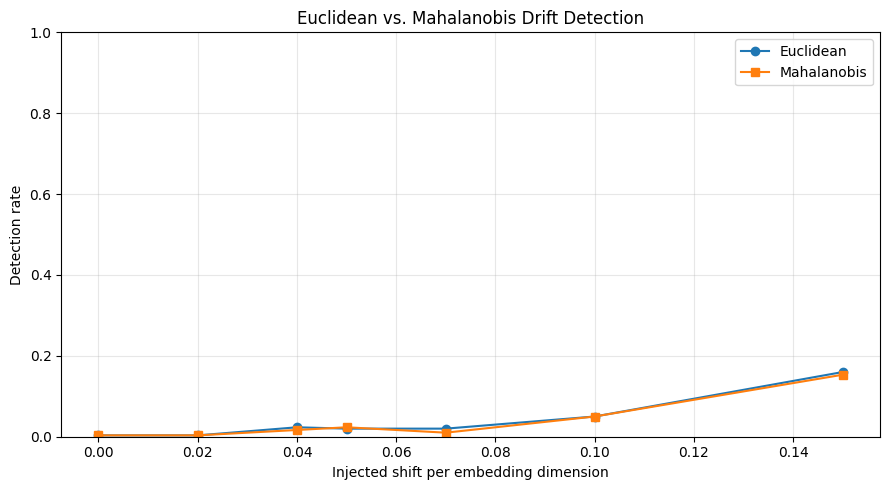

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["shift"],
    results_df["euclidean_detection_rate"],
    marker="o",
    label="Euclidean"
)

plt.plot(
    results_df["shift"],
    results_df["mahalanobis_detection_rate"],
    marker="s",
    label="Mahalanobis"
)

plt.xlabel("Injected shift per embedding dimension")
plt.ylabel("Detection rate")
plt.title("Euclidean vs. Mahalanobis Drift Detection")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# Independent no-drift evaluation
false_alarm_rng = np.random.default_rng(SEED + 3)

euclidean_false_alarms = 0
mahalanobis_false_alarms = 0
N_NO_DRIFT_TESTS = 2000

for _ in range(N_NO_DRIFT_TESTS):
    window = generate_window(
        false_alarm_rng,
        mean=np.zeros(EMBEDDING_DIM),
        window_size=WINDOW_SIZE,
        embedding_dim=EMBEDDING_DIM
    )

    current_mean = window.mean(axis=0)

    e_score = euclidean_score(reference_mean, current_mean)
    m_score = regularized_mahalanobis_score(
        reference_mean,
        current_mean,
        reference_covariance
    )

    euclidean_false_alarms += e_score > euclidean_threshold
    mahalanobis_false_alarms += m_score > mahalanobis_threshold

print("Independent no-drift evaluation")
print(f"Test windows: {N_NO_DRIFT_TESTS}")
print(
    "Euclidean false-alarm rate: "
    f"{euclidean_false_alarms / N_NO_DRIFT_TESTS:.4f}"
)
print(
    "Mahalanobis false-alarm rate: "
    f"{mahalanobis_false_alarms / N_NO_DRIFT_TESTS:.4f}"
)


Independent no-drift evaluation
Test windows: 2000
Euclidean false-alarm rate: 0.0090
Mahalanobis false-alarm rate: 0.0115


In [ ]:

# Multi-seed evaluation with independent reference, calibration,
# and test data for each seed.

multi_seed_results = []

for seed in range(SEED, SEED + N_SEEDS):
    local_rng = np.random.default_rng(seed)

    # Independent reference data for this seed
    reference = local_rng.normal(
        0.0, 1.0, size=(REFERENCE_SIZE, EMBEDDING_DIM)
    )
    ref_mean = reference.mean(axis=0)
    ref_cov = np.cov(reference, rowvar=False)

    # Independent calibration data
    calibration_rng_local = np.random.default_rng(seed + 1000)
    e_cal, m_cal = [], []

    for _ in range(CALIBRATION_WINDOWS):
        window = generate_window(
            calibration_rng_local, np.zeros(EMBEDDING_DIM),
            WINDOW_SIZE, EMBEDDING_DIM
        )
        current_mean = window.mean(axis=0)

        e_cal.append(euclidean_score(ref_mean, current_mean))
        m_cal.append(
            regularized_mahalanobis_score(ref_mean, current_mean, ref_cov)
        )

    e_threshold = np.quantile(e_cal, 0.99)
    m_threshold = np.quantile(m_cal, 0.99)

    # Independent test data at each shift
    test_rng_local = np.random.default_rng(seed + 2000)

    for shift in SHIFT_LEVELS:
        e_hits, m_hits = 0, 0

        for _ in range(TEST_WINDOWS):
            window = generate_window(
                test_rng_local,
                np.full(EMBEDDING_DIM, shift),
                WINDOW_SIZE,
                EMBEDDING_DIM
            )
            current_mean = window.mean(axis=0)

            e_hits += (
                euclidean_score(ref_mean, current_mean) > e_threshold
            )
            m_hits += (
                regularized_mahalanobis_score(
                    ref_mean, current_mean, ref_cov
                ) > m_threshold
            )

        multi_seed_results.append({
            "seed": seed,
            "shift": shift,
            "euclidean_rate": e_hits / TEST_WINDOWS,
            "mahalanobis_rate": m_hits / TEST_WINDOWS
        })

multi_seed_df = pd.DataFrame(multi_seed_results)

summary_df = (
    multi_seed_df.groupby("shift")
    .agg(
        euclidean_mean=("euclidean_rate", "mean"),
        euclidean_sd=("euclidean_rate", "std"),
        mahalanobis_mean=("mahalanobis_rate", "mean"),
        mahalanobis_sd=("mahalanobis_rate", "std")
    )
    .reset_index()
)

print("Multi-seed evaluation completed.")
display(summary_df.round(4))


Multi-seed evaluation completed.


,shift,euclidean_mean,euclidean_sd,mahalanobis_mean,mahalanobis_sd
0,0.00,0.0097,0.0071,0.0107,0.0089
1,0.02,0.0140,0.0054,0.0143,0.0079
2,0.04,0.0127,0.0070,0.0147,0.0071
3,0.05,0.0170,0.0084,0.0157,0.0077
4,0.07,0.0300,0.0110,0.0270,0.0096
5,0.10,0.0517,0.0248,0.0497,0.0224
6,0.15,0.1313,0.0303,0.1327,0.0442


In [ ]:

from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

multi_seed_df.to_csv(
    output_dir / "euclidean_mahalanobis_multi_seed_results.csv",
    index=False
)

summary_df.to_csv(
    output_dir / "euclidean_mahalanobis_multi_seed_summary.csv",
    index=False
)

print("Saved:")
print(output_dir / "euclidean_mahalanobis_multi_seed_results.csv")
print(output_dir / "euclidean_mahalanobis_multi_seed_summary.csv")


Saved:
results/euclidean_mahalanobis_multi_seed_results.csv
results/euclidean_mahalanobis_multi_seed_summary.csv


In [ ]:

from google.colab import files

files.download("results/euclidean_mahalanobis_multi_seed_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("results/euclidean_mahalanobis_multi_seed_summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Corrected calibration: use the estimated reference mean
# as the center of the calibration distribution.

corrected_calibration_rng = np.random.default_rng(SEED + 4000)

corrected_e_calibration_scores = []
corrected_m_calibration_scores = []

for _ in range(CALIBRATION_WINDOWS):
    window = generate_window(
        corrected_calibration_rng,
        mean=reference_mean,
        window_size=WINDOW_SIZE,
        embedding_dim=EMBEDDING_DIM
    )

    current_mean = window.mean(axis=0)

    corrected_e_calibration_scores.append(
        euclidean_score(reference_mean, current_mean)
    )

    corrected_m_calibration_scores.append(
        regularized_mahalanobis_score(
            reference_mean,
            current_mean,
            reference_covariance
        )
    )

corrected_euclidean_threshold = np.quantile(
    corrected_e_calibration_scores, 0.99
)

corrected_mahalanobis_threshold = np.quantile(
    corrected_m_calibration_scores, 0.99
)

print("Corrected calibration completed.")
print(f"Euclidean threshold: {corrected_euclidean_threshold:.4f}")
print(f"Mahalanobis threshold: {corrected_mahalanobis_threshold:.4f}")


Corrected calibration completed.
Euclidean threshold: 1.2686
Mahalanobis threshold: 1.2824


In [ ]:

corrected_multi_seed_results = []

for seed in range(SEED, SEED + N_SEEDS):
    # Independent reference sample for this seed
    ref_rng = np.random.default_rng(seed)
    reference = ref_rng.normal(
        0.0, 1.0, size=(REFERENCE_SIZE, EMBEDDING_DIM)
    )
    ref_mean = reference.mean(axis=0)
    ref_cov = np.cov(reference, rowvar=False)

    # Calibration windows centered on this seed's reference mean
    cal_rng = np.random.default_rng(seed + 1000)
    e_cal, m_cal = [], []

    for _ in range(CALIBRATION_WINDOWS):
        window = generate_window(
            cal_rng, ref_mean, WINDOW_SIZE, EMBEDDING_DIM
        )
        current_mean = window.mean(axis=0)

        e_cal.append(euclidean_score(ref_mean, current_mean))
        m_cal.append(
            regularized_mahalanobis_score(
                ref_mean, current_mean, ref_cov
            )
        )

    e_threshold = np.quantile(e_cal, 0.99)
    m_threshold = np.quantile(m_cal, 0.99)

    # Same test windows for both methods
    test_rng = np.random.default_rng(seed + 2000)

    for shift in SHIFT_LEVELS:
        e_hits, m_hits = 0, 0

        for _ in range(TEST_WINDOWS):
            window = generate_window(
                test_rng,
                ref_mean + np.full(EMBEDDING_DIM, shift),
                WINDOW_SIZE,
                EMBEDDING_DIM
            )
            current_mean = window.mean(axis=0)

            e_hits += (
                euclidean_score(ref_mean, current_mean) > e_threshold
            )
            m_hits += (
                regularized_mahalanobis_score(
                    ref_mean, current_mean, ref_cov
                ) > m_threshold
            )

        corrected_multi_seed_results.append({
            "seed": seed,
            "shift": shift,
            "euclidean_rate": e_hits / TEST_WINDOWS,
            "mahalanobis_rate": m_hits / TEST_WINDOWS
        })

corrected_multi_seed_df = pd.DataFrame(corrected_multi_seed_results)

corrected_summary_df = (
    corrected_multi_seed_df.groupby("shift")
    .agg(
        euclidean_mean=("euclidean_rate", "mean"),
        euclidean_sd=("euclidean_rate", "std"),
        mahalanobis_mean=("mahalanobis_rate", "mean"),
        mahalanobis_sd=("mahalanobis_rate", "std")
    )
    .reset_index()
)

print("Corrected multi-seed evaluation completed.")
display(corrected_summary_df.round(4))


Corrected multi-seed evaluation completed.


,shift,euclidean_mean,euclidean_sd,mahalanobis_mean,mahalanobis_sd
0,0.00,0.0120,0.0083,0.0107,0.0070
1,0.02,0.0117,0.0063,0.0103,0.0058
2,0.04,0.0163,0.0085,0.0147,0.0091
3,0.05,0.0200,0.0099,0.0173,0.0084
4,0.07,0.0313,0.0111,0.0270,0.0078
5,0.10,0.0547,0.0177,0.0473,0.0195
6,0.15,0.1410,0.0244,0.1310,0.0382


In [ ]:

from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

corrected_multi_seed_df.to_csv(
    output_dir / "corrected_euclidean_mahalanobis_multi_seed_results.csv",
    index=False
)

corrected_summary_df.to_csv(
    output_dir / "corrected_euclidean_mahalanobis_multi_seed_summary.csv",
    index=False
)

print("Corrected CSV files saved successfully.")


Corrected CSV files saved successfully.


In [ ]:

from google.colab import files

files.download(
    "results/corrected_euclidean_mahalanobis_multi_seed_results.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download(
    "results/corrected_euclidean_mahalanobis_multi_seed_summary.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

# Experiment 2: Compare different drift patterns
# Uses the reference data and corrected thresholds from the current notebook.

pattern_rng = np.random.default_rng(SEED + 5000)

drift_patterns = {
    "No drift": np.zeros(EMBEDDING_DIM),
    "Sparse shift (4 dims)": np.array(
        [0.15] * 4 + [0.0] * (EMBEDDING_DIM - 4)
    ),
    "Half-dimensional shift": np.array(
        [0.15] * (EMBEDDING_DIM // 2)
        + [0.0] * (EMBEDDING_DIM - EMBEDDING_DIM // 2)
    ),
    "Full-dimensional shift": np.full(EMBEDDING_DIM, 0.15)
}

pattern_results = []

for pattern_name, shift_vector in drift_patterns.items():
    e_hits = 0
    m_hits = 0

    for _ in range(TEST_WINDOWS):
        window = generate_window(
            pattern_rng,
            mean=reference_mean + shift_vector,
            window_size=WINDOW_SIZE,
            embedding_dim=EMBEDDING_DIM
        )

        current_mean = window.mean(axis=0)

        e_score = euclidean_score(reference_mean, current_mean)
        m_score = regularized_mahalanobis_score(
            reference_mean,
            current_mean,
            reference_covariance
        )

        e_hits += e_score > corrected_euclidean_threshold
        m_hits += m_score > corrected_mahalanobis_threshold

    pattern_results.append({
        "drift_pattern": pattern_name,
        "euclidean_detection_rate": e_hits / TEST_WINDOWS,
        "mahalanobis_detection_rate": m_hits / TEST_WINDOWS,
        "test_windows": TEST_WINDOWS
    })

pattern_results_df = pd.DataFrame(pattern_results)

print("Drift-pattern experiment completed.")
display(pattern_results_df.round(4))


Drift-pattern experiment completed.


,drift_pattern,euclidean_detection_rate,mahalanobis_detection_rate,test_windows
0,No drift,0.0100,0.0100,300
1,Sparse shift (4 dims),0.0333,0.0300,300
2,Half-dimensional shift,0.0533,0.0567,300
3,Full-dimensional shift,0.1500,0.1433,300


In [21]:

from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

pattern_results_df.to_csv(
    output_dir / "drift_pattern_comparison.csv",
    index=False
)

print("Saved results/drift_pattern_comparison.csv")


Saved results/drift_pattern_comparison.csv


In [22]:

# Experiment 3: Variance drift
# The mean remains at the reference mean, but variance increases.

variance_rng = np.random.default_rng(SEED + 6000)

variance_scales = [1.0, 1.1, 1.25, 1.5, 2.0]
variance_results = []

for scale in variance_scales:
    e_hits = 0
    m_hits = 0

    for _ in range(TEST_WINDOWS):
        window = variance_rng.normal(
            loc=reference_mean,
            scale=scale,
            size=(WINDOW_SIZE, EMBEDDING_DIM)
        )

        current_mean = window.mean(axis=0)

        e_score = euclidean_score(reference_mean, current_mean)
        m_score = regularized_mahalanobis_score(
            reference_mean,
            current_mean,
            reference_covariance
        )

        e_hits += e_score > corrected_euclidean_threshold
        m_hits += m_score > corrected_mahalanobis_threshold

    variance_results.append({
        "variance_scale": scale,
        "euclidean_detection_rate": e_hits / TEST_WINDOWS,
        "mahalanobis_detection_rate": m_hits / TEST_WINDOWS,
        "test_windows": TEST_WINDOWS
    })

variance_results_df = pd.DataFrame(variance_results)

print("Variance-drift experiment completed.")
display(variance_results_df.round(4))


Variance-drift experiment completed.


,variance_scale,euclidean_detection_rate,mahalanobis_detection_rate,test_windows
0,1.00,0.0200,0.0133,300
1,1.10,0.0467,0.0567,300
2,1.25,0.2333,0.2100,300
3,1.50,0.5467,0.5367,300
4,2.00,0.9500,0.9333,300


In [23]:

from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

variance_results_df.to_csv(
    output_dir / "variance_drift_comparison.csv",
    index=False
)

print("Saved results/variance_drift_comparison.csv")


Saved results/variance_drift_comparison.csv


In [24]:

# Variance-sensitive detector: compare average squared deviations
# from each sample's own mean.

def variance_score(reference_data, current_window):
    reference_spread = np.mean(
        np.sum(
            (reference_data - reference_data.mean(axis=0)) ** 2,
            axis=1
        )
    )

    current_spread = np.mean(
        np.sum(
            (current_window - current_window.mean(axis=0)) ** 2,
            axis=1
        )
    )

    return current_spread / reference_spread


# Calibrate the variance detector using no-drift windows
variance_calibration_rng = np.random.default_rng(SEED + 7000)
variance_calibration_scores = []

for _ in range(CALIBRATION_WINDOWS):
    window = generate_window(
        variance_calibration_rng,
        mean=reference_mean,
        window_size=WINDOW_SIZE,
        embedding_dim=EMBEDDING_DIM
    )

    variance_calibration_scores.append(
        variance_score(reference_data, window)
    )

variance_threshold = np.quantile(
    variance_calibration_scores, 0.99
)

print("Variance-sensitive detector calibrated.")
print(f"Variance ratio threshold: {variance_threshold:.4f}")


Variance-sensitive detector calibrated.
Variance ratio threshold: 1.1443


In [25]:

# Compare three detectors under variance drift
comparison_rng = np.random.default_rng(SEED + 8000)

three_detector_results = []

for scale in variance_scales:
    e_hits = 0
    m_hits = 0
    v_hits = 0

    for _ in range(TEST_WINDOWS):
        window = comparison_rng.normal(
            loc=reference_mean,
            scale=scale,
            size=(WINDOW_SIZE, EMBEDDING_DIM)
        )

        current_mean = window.mean(axis=0)

        e_score = euclidean_score(reference_mean, current_mean)
        m_score = regularized_mahalanobis_score(
            reference_mean,
            current_mean,
            reference_covariance
        )
        v_score = variance_score(reference_data, window)

        e_hits += e_score > corrected_euclidean_threshold
        m_hits += m_score > corrected_mahalanobis_threshold
        v_hits += v_score > variance_threshold

    three_detector_results.append({
        "variance_scale": scale,
        "euclidean_detection_rate": e_hits / TEST_WINDOWS,
        "mahalanobis_detection_rate": m_hits / TEST_WINDOWS,
        "variance_detection_rate": v_hits / TEST_WINDOWS,
        "test_windows": TEST_WINDOWS
    })

three_detector_results_df = pd.DataFrame(three_detector_results)

print("Three-detector comparison completed.")
display(three_detector_results_df.round(4))


Three-detector comparison completed.


,variance_scale,euclidean_detection_rate,mahalanobis_detection_rate,variance_detection_rate,test_windows
0,1.00,0.0067,0.0133,0.0000,300
1,1.10,0.0233,0.0300,0.4700,300
2,1.25,0.2100,0.1967,0.9967,300
3,1.50,0.5600,0.5467,1.0000,300
4,2.00,0.9533,0.9533,1.0000,300


In [26]:

from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

three_detector_results_df.to_csv(
    output_dir / "three_detector_variance_comparison.csv",
    index=False
)

print("Saved results/three_detector_variance_comparison.csv")


Saved results/three_detector_variance_comparison.csv


In [27]:

# Independent false-alarm validation for the variance detector

variance_validation_rng = np.random.default_rng(SEED + 9000)
N_VARIANCE_VALIDATION = 2000

variance_false_alarms = 0
validation_scores = []

for _ in range(N_VARIANCE_VALIDATION):
    window = generate_window(
        variance_validation_rng,
        mean=reference_mean,
        window_size=WINDOW_SIZE,
        embedding_dim=EMBEDDING_DIM
    )

    score = variance_score(reference_data, window)
    validation_scores.append(score)

    variance_false_alarms += score > variance_threshold

variance_false_alarm_rate = (
    variance_false_alarms / N_VARIANCE_VALIDATION
)

print("Variance detector false-alarm validation")
print(f"Validation windows: {N_VARIANCE_VALIDATION}")
print(f"False alarms: {variance_false_alarms}")
print(f"False-alarm rate: {variance_false_alarm_rate:.4f}")
print(f"Calibration target: 0.0100")


Variance detector false-alarm validation
Validation windows: 2000
False alarms: 15
False-alarm rate: 0.0075
Calibration target: 0.0100


In [28]:

# Multi-seed validation of the variance-sensitive detector

variance_multi_seed_results = []

for seed in range(SEED, SEED + N_SEEDS):
    local_rng = np.random.default_rng(seed + 10000)

    # Independent reference sample for this seed
    ref_data = local_rng.normal(
        0.0, 1.0, size=(REFERENCE_SIZE, EMBEDDING_DIM)
    )
    ref_mean = ref_data.mean(axis=0)

    # Calibrate the variance threshold on independent no-drift windows
    cal_rng = np.random.default_rng(seed + 11000)
    cal_scores = []

    for _ in range(CALIBRATION_WINDOWS):
        window = generate_window(
            cal_rng, ref_mean, WINDOW_SIZE, EMBEDDING_DIM
        )
        cal_scores.append(variance_score(ref_data, window))

    threshold = np.quantile(cal_scores, 0.99)

    # Evaluate independent test windows
    test_rng = np.random.default_rng(seed + 12000)

    for scale in variance_scales:
        detections = 0

        for _ in range(TEST_WINDOWS):
            window = test_rng.normal(
                loc=ref_mean,
                scale=scale,
                size=(WINDOW_SIZE, EMBEDDING_DIM)
            )

            detections += variance_score(ref_data, window) > threshold

        variance_multi_seed_results.append({
            "seed": seed,
            "variance_scale": scale,
            "detection_rate": detections / TEST_WINDOWS
        })

variance_multi_seed_df = pd.DataFrame(variance_multi_seed_results)

variance_multi_seed_summary = (
    variance_multi_seed_df.groupby("variance_scale")
    .agg(
        mean_detection_rate=("detection_rate", "mean"),
        sd_detection_rate=("detection_rate", "std")
    )
    .reset_index()
)

print("Multi-seed variance evaluation completed.")
display(variance_multi_seed_summary.round(4))


Multi-seed variance evaluation completed.


,variance_scale,mean_detection_rate,sd_detection_rate
0,1.00,0.0123,0.0086
1,1.10,0.5267,0.0625
2,1.25,0.9987,0.0023
3,1.50,1.0000,0.0000
4,2.00,1.0000,0.0000


In [29]:

from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

variance_multi_seed_df.to_csv(
    output_dir / "variance_drift_multi_seed_results.csv",
    index=False
)

variance_multi_seed_summary.to_csv(
    output_dir / "variance_drift_multi_seed_summary.csv",
    index=False
)

print("Saved:")
print("results/variance_drift_multi_seed_results.csv")
print("results/variance_drift_multi_seed_summary.csv")


Saved:
results/variance_drift_multi_seed_results.csv
results/variance_drift_multi_seed_summary.csv


In [30]:

from google.colab import files

files.download("results/variance_drift_multi_seed_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:

from google.colab import files

files.download("results/variance_drift_multi_seed_summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

# FINAL STANDARDIZED EVALUATION — SETUP
# Keep previous experiments unchanged.
# All three detectors will be calibrated independently
# against the same no-drift distribution.

import numpy as np
import pandas as pd
from pathlib import Path

FINAL_SEED = 2026
FINAL_N_SEEDS = 10
FINAL_REFERENCE_SIZE = 500
FINAL_CALIBRATION_WINDOWS = 2000
FINAL_TEST_WINDOWS = 1000
FINAL_WINDOW_SIZE = 20
FINAL_EMBEDDING_DIM = 16
FINAL_ALPHA = 0.01

FINAL_VARIANCE_SCALES = [1.0, 1.1, 1.25, 1.5, 2.0]
FINAL_MEAN_SHIFTS = [0.0, 0.02, 0.05, 0.10, 0.15]

print("Standardized evaluation configuration loaded.")
print(f"Seeds: {FINAL_N_SEEDS}")
print(f"Reference samples per seed: {FINAL_REFERENCE_SIZE}")
print(f"Calibration windows per seed: {FINAL_CALIBRATION_WINDOWS}")
print(f"Test windows per scenario: {FINAL_TEST_WINDOWS}")
print(f"Target false-alarm rate: {FINAL_ALPHA:.1%}")


Standardized evaluation configuration loaded.
Seeds: 10
Reference samples per seed: 500
Calibration windows per seed: 2000
Test windows per scenario: 1000
Target false-alarm rate: 1.0%


In [33]:

def final_euclidean_score(reference_mean, current_window):
    current_mean = current_window.mean(axis=0)
    return float(np.linalg.norm(current_mean - reference_mean))


def final_mahalanobis_score(
    reference_mean, current_window, reference_covariance
):
    current_mean = current_window.mean(axis=0)
    delta = current_mean - reference_mean

    # Regularized covariance for numerical stability
    ridge = 1e-6
    covariance = (
        reference_covariance
        + ridge * np.eye(len(reference_mean))
    )

    return float(
        np.sqrt(delta @ np.linalg.solve(covariance, delta))
    )


def final_variance_score(reference_data, current_window):
    # Average squared distance from each dataset's own mean
    reference_centered = (
        reference_data - reference_data.mean(axis=0)
    )
    current_centered = (
        current_window - current_window.mean(axis=0)
    )

    reference_spread = np.mean(np.sum(reference_centered**2, axis=1))
    current_spread = np.mean(np.sum(current_centered**2, axis=1))

    return float(current_spread / reference_spread)


print("All three standardized scoring functions are ready.")


All three standardized scoring functions are ready.


In [34]:

# STEP 3: Reference data and independent calibration

final_reference_rng = np.random.default_rng(FINAL_SEED)

final_reference_data = final_reference_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(FINAL_REFERENCE_SIZE, FINAL_EMBEDDING_DIM)
)

final_reference_mean = final_reference_data.mean(axis=0)
final_reference_covariance = np.cov(
    final_reference_data, rowvar=False
)

final_calibration_rng = np.random.default_rng(FINAL_SEED + 1)

final_e_calibration_scores = []
final_m_calibration_scores = []
final_v_calibration_scores = []

for _ in range(FINAL_CALIBRATION_WINDOWS):
    window = final_calibration_rng.normal(
        loc=0.0,
        scale=1.0,
        size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
    )

    final_e_calibration_scores.append(
        final_euclidean_score(final_reference_mean, window)
    )

    final_m_calibration_scores.append(
        final_mahalanobis_score(
            final_reference_mean,
            window,
            final_reference_covariance
        )
    )

    final_v_calibration_scores.append(
        final_variance_score(final_reference_data, window)
    )

final_e_threshold = np.quantile(
    final_e_calibration_scores, 1 - FINAL_ALPHA
)
final_m_threshold = np.quantile(
    final_m_calibration_scores, 1 - FINAL_ALPHA
)
final_v_threshold = np.quantile(
    final_v_calibration_scores, 1 - FINAL_ALPHA
)

final_thresholds_df = pd.DataFrame({
    "detector": ["Euclidean", "Mahalanobis", "Variance-sensitive"],
    "threshold": [
        final_e_threshold,
        final_m_threshold,
        final_v_threshold
    ],
    "calibration_windows": [FINAL_CALIBRATION_WINDOWS] * 3,
    "target_false_alarm_rate": [FINAL_ALPHA] * 3
})

print("Calibration completed.")
display(final_thresholds_df.round(4))


Calibration completed.


,detector,threshold,calibration_windows,target_false_alarm_rate
0,Euclidean,1.3120,2000,0.01
1,Mahalanobis,1.3209,2000,0.01
2,Variance-sensitive,1.1186,2000,0.01


In [35]:

# STEP 4: Standardized multi-seed evaluation

final_results = []

for seed in range(FINAL_SEED, FINAL_SEED + FINAL_N_SEEDS):
    # Independent reference data
    ref_rng = np.random.default_rng(seed)
    ref_data = ref_rng.normal(
        0.0, 1.0,
        size=(FINAL_REFERENCE_SIZE, FINAL_EMBEDDING_DIM)
    )
    ref_mean = ref_data.mean(axis=0)
    ref_cov = np.cov(ref_data, rowvar=False)

    # Independent calibration data: no drift
    cal_rng = np.random.default_rng(seed + 10000)
    e_cal, m_cal, v_cal = [], [], []

    for _ in range(FINAL_CALIBRATION_WINDOWS):
        window = cal_rng.normal(
            0.0, 1.0,
            size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
        )

        e_cal.append(final_euclidean_score(ref_mean, window))
        m_cal.append(final_mahalanobis_score(ref_mean, window, ref_cov))
        v_cal.append(final_variance_score(ref_data, window))

    e_thr = np.quantile(e_cal, 1 - FINAL_ALPHA)
    m_thr = np.quantile(m_cal, 1 - FINAL_ALPHA)
    v_thr = np.quantile(v_cal, 1 - FINAL_ALPHA)

    test_rng = np.random.default_rng(seed + 20000)

    scenarios = []

    # Mean drift: shift every dimension equally
    for shift in FINAL_MEAN_SHIFTS:
        scenarios.append((
            "mean_drift", shift,
            ref_mean + np.full(FINAL_EMBEDDING_DIM, shift), 1.0
        ))

    # Variance drift: retain the reference mean, change spread
    for scale in FINAL_VARIANCE_SCALES:
        scenarios.append((
            "variance_drift", scale, ref_mean, scale
        ))

    for scenario, level, location, scale in scenarios:
        e_hits = m_hits = v_hits = 0

        for _ in range(FINAL_TEST_WINDOWS):
            window = test_rng.normal(
                loc=location,
                scale=scale,
                size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
            )

            e_hits += (
                final_euclidean_score(ref_mean, window) > e_thr
            )
            m_hits += (
                final_mahalanobis_score(ref_mean, window, ref_cov) > m_thr
            )
            v_hits += (
                final_variance_score(ref_data, window) > v_thr
            )

        final_results.append({
            "seed": seed,
            "scenario": scenario,
            "level": level,
            "euclidean_rate": e_hits / FINAL_TEST_WINDOWS,
            "mahalanobis_rate": m_hits / FINAL_TEST_WINDOWS,
            "variance_rate": v_hits / FINAL_TEST_WINDOWS
        })

final_results_df = pd.DataFrame(final_results)

final_summary_df = (
    final_results_df.groupby(["scenario", "level"])
    .agg(
        euclidean_mean=("euclidean_rate", "mean"),
        euclidean_sd=("euclidean_rate", "std"),
        mahalanobis_mean=("mahalanobis_rate", "mean"),
        mahalanobis_sd=("mahalanobis_rate", "std"),
        variance_mean=("variance_rate", "mean"),
        variance_sd=("variance_rate", "std")
    )
    .reset_index()
)

print("Standardized multi-seed evaluation completed.")
display(final_summary_df.round(4))


Standardized multi-seed evaluation completed.


,scenario,level,euclidean_mean,euclidean_sd,mahalanobis_mean,mahalanobis_sd,variance_mean,variance_sd
0,mean_drift,0.00,0.0087,0.0033,0.0075,0.0024,0.0099,0.0055
1,mean_drift,0.02,0.0081,0.0040,0.0081,0.0043,0.0086,0.0041
2,mean_drift,0.05,0.0111,0.0055,0.0099,0.0046,0.0083,0.0029
3,mean_drift,0.10,0.0328,0.0092,0.0283,0.0113,0.0091,0.0048
4,mean_drift,0.15,0.1055,0.0192,0.0918,0.0247,0.0101,0.0034
5,variance_drift,1.00,0.0075,0.0052,0.0073,0.0035,0.0097,0.0032
6,variance_drift,1.10,0.0370,0.0071,0.0359,0.0098,0.5383,0.0289
7,variance_drift,1.25,0.1768,0.0407,0.1666,0.0388,0.9992,0.0013
8,variance_drift,1.50,0.5353,0.0333,0.5192,0.0430,1.0000,0.0000
9,variance_drift,2.00,0.9400,0.0109,0.9322,0.0121,1.0000,0.0000


In [36]:

# STEP 5: Independent no-drift check for the current seed

diagnostic_rng = np.random.default_rng(FINAL_SEED + 30000)

N_DIAGNOSTIC_WINDOWS = 5000
diagnostic_e = 0
diagnostic_m = 0
diagnostic_v = 0

for _ in range(N_DIAGNOSTIC_WINDOWS):
    window = diagnostic_rng.normal(
        loc=final_reference_mean,
        scale=1.0,
        size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
    )

    diagnostic_e += (
        final_euclidean_score(final_reference_mean, window)
        > final_e_threshold
    )

    diagnostic_m += (
        final_mahalanobis_score(
            final_reference_mean,
            window,
            final_reference_covariance
        )
        > final_m_threshold
    )

    diagnostic_v += (
        final_variance_score(final_reference_data, window)
        > final_v_threshold
    )

print("Independent no-drift diagnostic")
print(f"Test windows: {N_DIAGNOSTIC_WINDOWS}")
print(f"Euclidean false-alarm rate: {diagnostic_e / N_DIAGNOSTIC_WINDOWS:.4f}")
print(f"Mahalanobis false-alarm rate: {diagnostic_m / N_DIAGNOSTIC_WINDOWS:.4f}")
print(f"Variance-sensitive false-alarm rate: {diagnostic_v / N_DIAGNOSTIC_WINDOWS:.4f}")
print("Target false-alarm rate: 0.0100")


Independent no-drift diagnostic
Test windows: 5000
Euclidean false-alarm rate: 0.0036
Mahalanobis false-alarm rate: 0.0054
Variance-sensitive false-alarm rate: 0.0120
Target false-alarm rate: 0.0100


In [37]:
# Verify the calibration thresholds using correctly centered windows

corrected_rng = np.random.default_rng(FINAL_SEED + 40000)

corrected_e_scores = []
corrected_m_scores = []
corrected_v_scores = []

for _ in range(FINAL_CALIBRATION_WINDOWS):
    window = corrected_rng.normal(
        loc=final_reference_mean,
        scale=1.0,
        size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
    )

    corrected_e_scores.append(
        final_euclidean_score(final_reference_mean, window)
    )

    corrected_m_scores.append(
        final_mahalanobis_score(
            final_reference_mean,
            window,
            final_reference_covariance
        )
    )

    corrected_v_scores.append(
        final_variance_score(final_reference_data, window)
    )

corrected_e_threshold = np.quantile(
    corrected_e_scores, 1 - FINAL_ALPHA
)
corrected_m_threshold = np.quantile(
    corrected_m_scores, 1 - FINAL_ALPHA
)
corrected_v_threshold = np.quantile(
    corrected_v_scores, 1 - FINAL_ALPHA
)

print("Corrected thresholds")
print(f"Euclidean: {corrected_e_threshold:.4f}")
print(f"Mahalanobis: {corrected_m_threshold:.4f}")
print(f"Variance-sensitive: {corrected_v_threshold:.4f}")

Corrected thresholds
Euclidean: 1.2862
Mahalanobis: 1.3137
Variance-sensitive: 1.1210


In [38]:

# Corrected standardized multi-seed evaluation
# Keeps the earlier exploratory results intact.

final_results_corrected = []

for seed in range(FINAL_SEED, FINAL_SEED + FINAL_N_SEEDS):
    # 1. Generate reference data
    ref_rng = np.random.default_rng(seed)
    ref_data = ref_rng.normal(
        0, 1,
        size=(FINAL_REFERENCE_SIZE, FINAL_EMBEDDING_DIM)
    )
    ref_mean = ref_data.mean(axis=0)
    ref_cov = np.cov(ref_data, rowvar=False)

    # 2. Calibrate all detectors on correctly centered no-drift windows
    cal_rng = np.random.default_rng(seed + 10000)
    e_cal, m_cal, v_cal = [], [], []

    for _ in range(FINAL_CALIBRATION_WINDOWS):
        window = cal_rng.normal(
            loc=ref_mean,
            scale=1.0,
            size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
        )

        e_cal.append(final_euclidean_score(ref_mean, window))
        m_cal.append(
            final_mahalanobis_score(ref_mean, window, ref_cov)
        )
        v_cal.append(final_variance_score(ref_data, window))

    e_threshold = np.quantile(e_cal, 1 - FINAL_ALPHA)
    m_threshold = np.quantile(m_cal, 1 - FINAL_ALPHA)
    v_threshold = np.quantile(v_cal, 1 - FINAL_ALPHA)

    # 3. Evaluate on independent test windows
    test_rng = np.random.default_rng(seed + 20000)

    scenarios = (
        [("mean_drift", shift) for shift in FINAL_MEAN_SHIFTS]
        + [("variance_drift", scale)
           for scale in FINAL_VARIANCE_SCALES]
    )

    for scenario, level in scenarios:
        e_alerts, m_alerts, v_alerts = 0, 0, 0

        for _ in range(FINAL_TEST_WINDOWS):
            if scenario == "mean_drift":
                window_mean = ref_mean + np.full(
                    FINAL_EMBEDDING_DIM, level
                )
                window = test_rng.normal(
                    loc=window_mean,
                    scale=1.0,
                    size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
                )
            else:
                window = test_rng.normal(
                    loc=ref_mean,
                    scale=level,
                    size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
                )

            e_alerts += (
                final_euclidean_score(ref_mean, window) > e_threshold
            )
            m_alerts += (
                final_mahalanobis_score(ref_mean, window, ref_cov)
                > m_threshold
            )
            v_alerts += (
                final_variance_score(ref_data, window) > v_threshold
            )

        final_results_corrected.append({
            "seed": seed,
            "scenario": scenario,
            "level": level,
            "euclidean_detection_rate": e_alerts / FINAL_TEST_WINDOWS,
            "mahalanobis_detection_rate": m_alerts / FINAL_TEST_WINDOWS,
            "variance_detection_rate": v_alerts / FINAL_TEST_WINDOWS,
        })

corrected_results_df = pd.DataFrame(final_results_corrected)

corrected_summary = (
    corrected_results_df
    .groupby(["scenario", "level"])[
        [
            "euclidean_detection_rate",
            "mahalanobis_detection_rate",
            "variance_detection_rate",
        ]
    ]
    .agg(["mean", "std"])
    .round(4)
)

display(corrected_summary)


euclidean_detection_rate          \
                                         mean     std   
scenario       level                                    
mean_drift     0.00                    0.0120  0.0042   
               0.02                    0.0123  0.0057   
               0.05                    0.0175  0.0044   
               0.10                    0.0429  0.0116   
               0.15                    0.1336  0.0171   
variance_drift 1.00                    0.0112  0.0050   
               1.10                    0.0473  0.0069   
               1.25                    0.2113  0.0374   
               1.50                    0.5798  0.0285   
               2.00                    0.9509  0.0079   

                     mahalanobis_detection_rate          \
                                           mean     std   
scenario       level                                      
mean_drift     0.00                      0.0105  0.0048   
               0.02                      0.0122  0.0069   
               0.05                      0.0144  0.0040   
               0.10                      0.0389  0.0155   
               0.15                      0.1138  0.0189   
variance_drift 1.00                      0.0111  0.0039   
               1.10                      0.0444  0.0078   
               1.25                      0.1943  0.0369   
               1.50                      0.5585  0.0302   
               2.00                      0.9427  0.0097   

                     variance_detection_rate          
                                        mean     std  
scenario       level                                  
mean_drift     0.00                   0.0099  0.0055  
               0.02                   0.0086  0.0041  
               0.05                   0.0083  0.0029  
               0.10                   0.0091  0.0048  
               0.15                   0.0101  0.0034  
variance_drift 1.00                   0.0097  0.0032  
               1.10                   0.5383  0.0289  
               1.25                   0.9992  0.0013  
               1.50                   1.0000  0.0000  
               2.00                   1.0000  0.0000

In [39]:

# Independent no-drift validation across all seeds

validation_rows = []

for seed in range(FINAL_SEED, FINAL_SEED + FINAL_N_SEEDS):
    ref_rng = np.random.default_rng(seed)
    ref_data = ref_rng.normal(
        0, 1,
        size=(FINAL_REFERENCE_SIZE, FINAL_EMBEDDING_DIM)
    )
    ref_mean = ref_data.mean(axis=0)
    ref_cov = np.cov(ref_data, rowvar=False)

    # Recreate thresholds using correctly centered calibration windows
    cal_rng = np.random.default_rng(seed + 10000)
    e_cal, m_cal, v_cal = [], [], []

    for _ in range(FINAL_CALIBRATION_WINDOWS):
        window = cal_rng.normal(
            loc=ref_mean,
            scale=1.0,
            size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
        )
        e_cal.append(final_euclidean_score(ref_mean, window))
        m_cal.append(
            final_mahalanobis_score(ref_mean, window, ref_cov)
        )
        v_cal.append(final_variance_score(ref_data, window))

    e_threshold = np.quantile(e_cal, 1 - FINAL_ALPHA)
    m_threshold = np.quantile(m_cal, 1 - FINAL_ALPHA)
    v_threshold = np.quantile(v_cal, 1 - FINAL_ALPHA)

    # Independent validation windows
    val_rng = np.random.default_rng(seed + 30000)
    e_alerts = m_alerts = v_alerts = 0
    n_validation = 5000

    for _ in range(n_validation):
        window = val_rng.normal(
            loc=ref_mean,
            scale=1.0,
            size=(FINAL_WINDOW_SIZE, FINAL_EMBEDDING_DIM)
        )

        e_alerts += (
            final_euclidean_score(ref_mean, window) > e_threshold
        )
        m_alerts += (
            final_mahalanobis_score(ref_mean, window, ref_cov)
            > m_threshold
        )
        v_alerts += (
            final_variance_score(ref_data, window) > v_threshold
        )

    validation_rows.append({
        "seed": seed,
        "euclidean_false_alarm_rate": e_alerts / n_validation,
        "mahalanobis_false_alarm_rate": m_alerts / n_validation,
        "variance_false_alarm_rate": v_alerts / n_validation,
    })

validation_df = pd.DataFrame(validation_rows)

display(validation_df.round(4))

print("\nMean false-alarm rates across seeds:")
display(
    validation_df.drop(columns="seed").mean().to_frame("mean_rate").round(4)
)


,seed,euclidean_false_alarm_rate,mahalanobis_false_alarm_rate,variance_false_alarm_rate
0,2026,0.0166,0.0166,0.0084
1,2027,0.0100,0.0092,0.0140
2,2028,0.0144,0.0132,0.0092
3,2029,0.0116,0.0112,0.0108
4,2030,0.0056,0.0072,0.0134
5,2031,0.0112,0.0082,0.0088
6,2032,0.0102,0.0094,0.0084
7,2033,0.0090,0.0084,0.0130
8,2034,0.0084,0.0072,0.0094
9,2035,0.0126,0.0102,0.0144



Mean false-alarm rates across seeds:


,mean_rate
euclidean_false_alarm_rate,0.0110
mahalanobis_false_alarm_rate,0.0101
variance_false_alarm_rate,0.0110


In [40]:

from pathlib import Path

# Save corrected outputs without overwriting earlier experiments
results_dir = Path("results_corrected")
results_dir.mkdir(parents=True, exist_ok=True)

corrected_results_df.to_csv(
    results_dir / "corrected_multiseed_detection_results.csv",
    index=False
)

validation_df.to_csv(
    results_dir / "independent_false_alarm_validation.csv",
    index=False
)

corrected_summary.to_csv(
    results_dir / "corrected_detection_summary.csv"
)

print("Saved corrected experiment files:")
for path in sorted(results_dir.glob("*.csv")):
    print(f"{path} ({path.stat().st_size:,} bytes)")


Saved corrected experiment files:
results_corrected/corrected_detection_summary.csv (783 bytes)
results_corrected/corrected_multiseed_detection_results.csv (4,050 bytes)
results_corrected/independent_false_alarm_validation.csv (342 bytes)


In [42]:

from google.colab import files
from pathlib import Path

results_dir = Path("results_corrected")

for path in sorted(results_dir.glob("*.csv")):
    files.download(str(path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>